# Linear and Ridge Regression

Cross-validation experiments for heating- and cooling-load prediction.

## Setup

Shared data tools and the libraries used for modeling and evaluation.

In [1]:
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make the shared src package importable
cwd = Path.cwd().resolve()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data import load_data, create_dev_test_split
from src.config import FEATURE_COLUMNS, TARGET_COLUMNS, N_FOLDS

print("Imports successful")

Imports successful


## Development data and cross-validation folds

The test set remains separate while the development set is divided into five folds.

In [2]:
df = load_data()

X_dev, X_test, y_dev, y_test = create_dev_test_split(df)

print("Development features:", X_dev.shape)
print("Development targets:", y_dev.shape)
print("Test features:", X_test.shape)
print("Test targets:", y_test.shape)

cv = KFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, val_idx) in enumerate(cv.split(X_dev), start=1):
    print(
        f"Fold {fold}: "
        f"{len(train_idx)} training, "
        f"{len(val_idx)} validation"
    )

Development features: (614, 8)
Development targets: (614, 2)
Test features: (154, 8)
Test targets: (154, 2)
Fold 1: 491 training, 123 validation
Fold 2: 491 training, 123 validation
Fold 3: 491 training, 123 validation
Fold 4: 491 training, 123 validation
Fold 5: 492 training, 122 validation


## One-fold example

One heating-load model, including its learned coefficients and validation error.

In [3]:
train_idx, val_idx = next(cv.split(X_dev))

X_train = X_dev.iloc[train_idx]
X_val = X_dev.iloc[val_idx]

y_train = y_dev["heating_load"].iloc[train_idx]
y_val = y_dev["heating_load"].iloc[val_idx]

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_val)

print("Intercept:", model.intercept_)

coefficients = pd.Series(
    model.coef_,
    index=FEATURE_COLUMNS
)

print(coefficients)

Intercept: 82.01129323647373
relative_compactness        -63.754937
surface_area                 -0.061393
wall_area                     0.037588
roof_area                    -0.049491
overall_height                4.146491
orientation                  -0.087611
glazing_area                 20.241286
glazing_area_distribution     0.252707
dtype: float64


In [4]:
mae = mean_absolute_error(y_val, predictions)
rmse = mean_squared_error(y_val, predictions) ** 0.5
r2 = r2_score(y_val, predictions)

print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

comparison = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Predicted": predictions,
    "Error": predictions - y_val.to_numpy()
})

comparison.head(10)

MAE:  1.953
RMSE: 2.807
R²:   0.928


,Actual,Predicted,Error
0,29.27,29.099198,-0.170802
1,35.96,32.882452,-3.077548
2,16.84,14.871303,-1.968697
3,15.16,12.165302,-2.994698
4,33.28,34.083473,0.803473
5,14.17,14.535430,0.365430
6,32.68,30.109091,-2.570909
7,10.43,7.539828,-2.890172
8,24.40,25.083937,0.683937
9,12.72,12.422088,-0.297912


## Five-fold linear regression

The cross-validation experiment fits one model per fold for each target (10 fits).

In [5]:
results = []

for target in TARGET_COLUMNS:

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_dev), start=1
    ):

        X_train = X_dev.iloc[train_idx]
        X_val = X_dev.iloc[val_idx]

        y_train = y_dev[target].iloc[train_idx]
        y_val = y_dev[target].iloc[val_idx]

        # New model for every fold
        model = LinearRegression()

        # Time model training
        start = perf_counter()
        model.fit(X_train, y_train)
        train_time = perf_counter() - start

        # Time prediction
        start = perf_counter()
        predictions = model.predict(X_val)
        prediction_time = perf_counter() - start

        results.append({
            "target": target,
            "model": "linear",
            "n_features": len(FEATURE_COLUMNS),
            "fold": fold,
            "model_seed": None,
            "mae": mean_absolute_error(y_val, predictions),
            "rmse": mean_squared_error(y_val, predictions) ** 0.5,
            "r2": r2_score(y_val, predictions),
            "train_time": train_time,
            "prediction_time": prediction_time,
        })

results_df = pd.DataFrame(results)

results_df

,target,model,n_features,fold,model_seed,mae,rmse,r2,train_time,prediction_time
0,heating_load,linear,8,1,None,1.952503,2.807182,0.927563,0.005410,0.002650
1,heating_load,linear,8,2,None,2.207098,3.167539,0.901554,0.004543,0.001108
2,heating_load,linear,8,3,None,2.118423,2.999942,0.908954,0.004522,0.002898
3,heating_load,linear,8,4,None,1.967580,2.706379,0.927574,0.003503,0.001958
4,heating_load,linear,8,5,None,2.063500,2.898087,0.907392,0.003786,0.002623
5,cooling_load,linear,8,1,None,2.149245,3.111927,0.895794,0.006119,0.002888
6,cooling_load,linear,8,2,None,2.191851,3.183584,0.886431,0.004832,0.001160
7,cooling_load,linear,8,3,None,2.559847,3.555193,0.860769,0.002880,0.001331
8,cooling_load,linear,8,4,None,2.382436,3.224160,0.889331,0.006507,0.002632
9,cooling_load,linear,8,5,None,2.103277,3.039817,0.882189,0.005647,0.002502


## Cross-validation summary

Bars show the fold means; error bars show one standard deviation.

mae          rmse            r2       
               mean    std   mean    std   mean    std
target                                                
heating_load  2.062  0.106  2.916  0.178  0.915  0.012
cooling_load  2.277  0.190  3.223  0.199  0.883  0.013

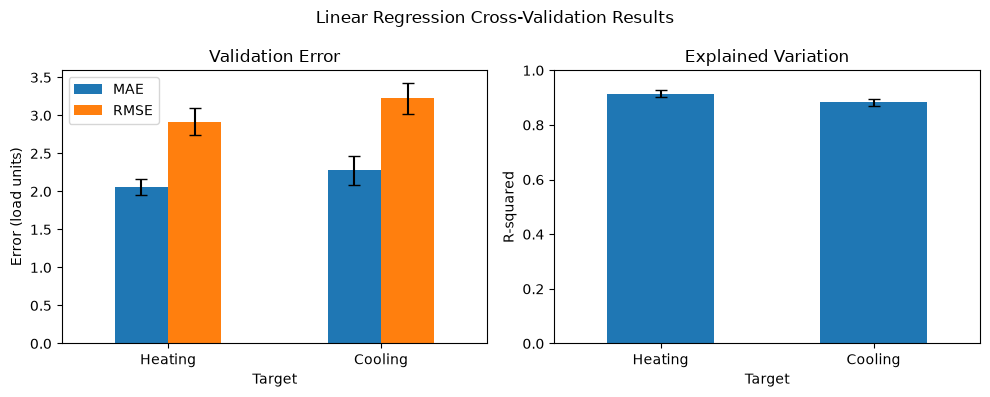

In [6]:
summary = results_df.groupby("target")[
    ["mae", "rmse", "r2"]
].agg(["mean", "std"]).loc[TARGET_COLUMNS]

display(summary.round(3))

mean_scores = results_df.groupby("target")[["mae", "rmse", "r2"]].mean().loc[TARGET_COLUMNS]
std_scores = results_df.groupby("target")[["mae", "rmse", "r2"]].std().loc[TARGET_COLUMNS]
target_labels = ["Heating", "Cooling"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

mean_scores[["mae", "rmse"]].plot.bar(
    yerr=std_scores[["mae", "rmse"]],
    capsize=4,
    rot=0,
    ax=axes[0],
)
axes[0].set_title("Validation Error")
axes[0].set_xlabel("Target")
axes[0].set_ylabel("Error (load units)")
axes[0].set_xticklabels(target_labels)
axes[0].legend(["MAE", "RMSE"])

mean_scores[["r2"]].plot.bar(
    yerr=std_scores[["r2"]],
    capsize=4,
    rot=0,
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Explained Variation")
axes[1].set_xlabel("Target")
axes[1].set_ylabel("R-squared")
axes[1].set_xticklabels(target_labels)
axes[1].set_ylim(0, 1)

fig.suptitle("Linear Regression Cross-Validation Results")
fig.tight_layout()
plt.show()

## Baseline review

- **Heating versus cooling:** Cooling is somewhat harder to predict, but the difference is not substantial. Its mean MAE and RMSE are about 10% higher than heating's, while mean R-squared is 0.883 compared with 0.915 for heating.
- **Consistency across folds:** Performance is reasonably consistent. Heating R-squared ranges from 0.902 to 0.928, and cooling ranges from 0.861 to 0.896. Cooling fold 3 is the weakest result (MAE 2.560, RMSE 3.555, R-squared 0.861), but it is not an extreme outlier.
- **Baseline quality:** Linear regression provides a sensible baseline. It explains about 91% of the heating-load variation and 88% of the cooling-load variation, leaving a useful benchmark for Ridge and Random Forest.
- **Timing:** Training and prediction take only a few milliseconds, so overhead and normal system activity create substantial relative noise. These measurements show that linear regression is fast, but repeated timings would be needed for precise comparisons between similarly fast models.
- **Correlated predictors:** Several architectural features are strongly related. Relative compactness and surface area have a correlation of -0.992, while roof area and overall height have a correlation of -0.973. Surface area also equals wall area plus twice the roof area in this dataset. This multicollinearity can make individual linear coefficients unstable or difficult to interpret even when predictions remain accurate. Ridge regression is the next experiment because its coefficient penalty is designed to reduce this instability.

## Fold-level results

Saved for later comparison with Ridge and Random Forest results.

In [7]:
output_path = project_root / "results" / "tables" / "linear_baseline_cv.csv"

output_path.parent.mkdir(parents=True, exist_ok=True)

results_df.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: C:\Senior Year\ELEG405\eleg405-energy-load-prediction\results\tables\linear_baseline_cv.csv


# Ridge Regression - Initial Experiment

In [16]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

creating the ridge pipleine. This describes two sequential operations: StandardScaler (fits means and standard deviations on training fold only) and Ridge (learn regularized coeffcieints from training fold)

In [ ]:
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

Fve-fold evaluation with ridge

In [17]:
ridge_results = []

for target in TARGET_COLUMNS:

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_dev), start=1
    ):
        X_train = X_dev.iloc[train_idx]
        X_val = X_dev.iloc[val_idx]

        y_train = y_dev[target].iloc[train_idx]
        y_val = y_dev[target].iloc[val_idx]

        # Fresh pipeline for each fold
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=1.0)),
        ])

        # Time fitting, including scaling
        start = perf_counter()
        model.fit(X_train, y_train)
        train_time = perf_counter() - start

        # Time prediction, including scaling
        start = perf_counter()
        predictions = model.predict(X_val)
        prediction_time = perf_counter() - start

        ridge_results.append({
            "target": target,
            "model": "ridge",
            "n_features": 8,
            "fold": fold,
            "model_seed": None,
            "mae": mean_absolute_error(y_val, predictions),
            "rmse": mean_squared_error(y_val, predictions) ** 0.5,
            "r2": r2_score(y_val, predictions),
            "train_time": train_time,
            "prediction_time": prediction_time,
        })

ridge_results_df = pd.DataFrame(ridge_results)
ridge_results_df

,target,model,n_features,fold,model_seed,mae,rmse,r2,train_time,prediction_time
0,heating_load,ridge,8,1,None,1.948367,2.803734,0.927741,0.159887,0.009611
1,heating_load,ridge,8,2,None,2.205098,3.163777,0.901788,0.007790,0.002121
2,heating_load,ridge,8,3,None,2.103944,3.000090,0.908945,0.004576,0.001068
3,heating_load,ridge,8,4,None,1.975944,2.729299,0.926342,0.003325,0.001184
4,heating_load,ridge,8,5,None,2.066866,2.896513,0.907492,0.003729,0.001404
5,cooling_load,ridge,8,1,None,2.160015,3.107007,0.896124,0.004238,0.001219
6,cooling_load,ridge,8,2,None,2.177796,3.178369,0.886803,0.004268,0.001270
7,cooling_load,ridge,8,3,None,2.551505,3.559776,0.860410,0.002923,0.001166
8,cooling_load,ridge,8,4,None,2.396373,3.243140,0.888024,0.004067,0.001205
9,cooling_load,ridge,8,5,None,2.120378,3.041900,0.882027,0.003101,0.001153


Compare ridge against linear regression

In [21]:
comparison_df = pd.concat(
    [results_df, ridge_results_df],
    ignore_index=True
)

summary = (
    comparison_df
    .groupby(["target", "model"])[["mae", "rmse", "r2"]]
    .agg(["mean", "std"])
)

summary.round(3)

mae          rmse            r2       
                      mean    std   mean    std   mean    std
target       model                                           
cooling_load linear  2.277  0.190  3.223  0.199  0.883  0.013
             ridge   2.281  0.185  3.226  0.201  0.883  0.013
heating_load linear  2.062  0.106  2.916  0.178  0.915  0.012
             ridge   2.060  0.103  2.919  0.170  0.914  0.012

In [20]:
mean_rmse = (
    comparison_df
    .groupby(["target", "model"])["rmse"]
    .mean()
    .unstack()
)

mean_rmse["ridge_minus_linear"] = (
    mean_rmse["ridge"] - mean_rmse["linear"]
)

mean_rmse.round(4)

model,linear,ridge,ridge_minus_linear
target,,,
cooling_load,3.2229,3.2260,0.0031
heating_load,2.9158,2.9187,0.0029


In [23]:
output_path = (
    project_root / "results" / "tables" / "ridge_initial_cv.csv"
)

ridge_results_df.to_csv(output_path, index=False)
print("Saved:", output_path)

Saved: C:\Senior Year\ELEG405\eleg405-energy-load-prediction\results\tables\ridge_initial_cv.csv


In [22]:
train_idx, val_idx = next(cv.split(X_dev))

X_train = X_dev.iloc[train_idx]
y_train = y_dev["heating_load"].iloc[train_idx]

model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0)),
])

model.fit(X_train, y_train)

ridge_coefficients = pd.Series(
    model.named_steps["model"].coef_,
    index=FEATURE_COLUMNS
)

ridge_coefficients

relative_compactness        -5.341374
surface_area                -2.760724
wall_area                    1.014196
roof_area                   -3.196141
overall_height               7.585335
orientation                 -0.095945
glazing_area                 2.719750
glazing_area_distribution    0.390584
dtype: float64